# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [1]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  +1.9610  F =  +59.1376  |diff| = 2.8e-07
r = 1.12  U =  -0.9998  F =   +0.1440  |diff| = 1.9e-08
r = 1.50  U =  -0.3203  F =   -1.1580  |diff| = 2.6e-10
r = 2.00  U =  -0.0615  F =   -0.1816  |diff| = 4.0e-11
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -1.0


**Your turn.** Replace the potential by a Morse potential $U=(1-e^{-2(r-1)})^2-1$ and its derivative. Where is the force zero?

In [2]:
U  = lambda r: (1 - np.exp(-2 * (r - 1)))**2 - 1
dU = lambda r: -4 * np.exp(-2 * (r - 1)) * (1 - np.exp(-2 * (r - 1)))

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  -0.9889  F =   -0.4649  |diff| = 9.3e-01
r = 1.12  U =  -0.9545  F =   +0.6714  |diff| = 1.3e+00
r = 1.50  U =  -0.6004  F =   +0.9302  |diff| = 1.9e+00
r = 2.00  U =  -0.2524  F =   +0.4681  |diff| = 9.4e-01
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -0.9528


---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

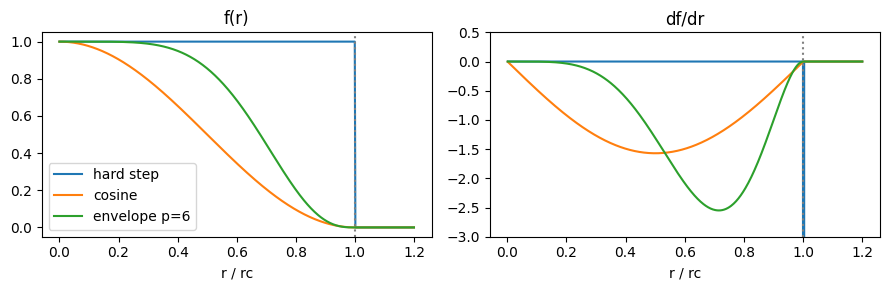

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** The hard step's derivative is a spike (a delta function) at $r_c$. What would that mean for the force on an atom crossing the cutoff during MD?

A discontinuous step in potential energy at rc produces an infinite and strong force spice, like a Dirac Delta function whenever an atom crosses the cutoff radius.



---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

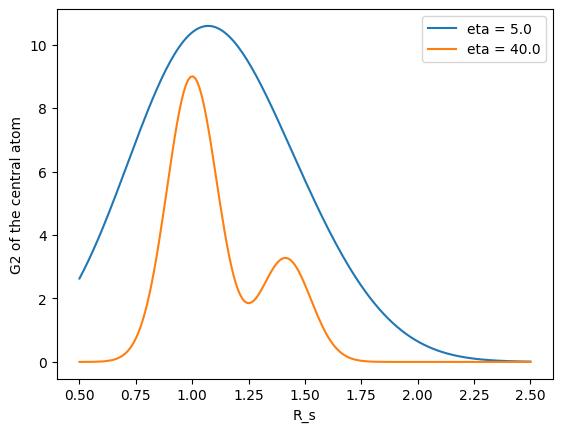

In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

**Your turn.** Remove the 6 second-shell atoms. Which peak disappears? With $\eta=5$, can you still tell the two shells apart?

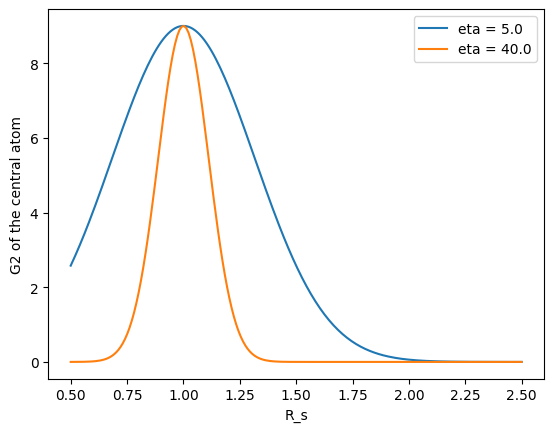

In [5]:
fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

# atom 0 at the centre of a small fcc-like cluster: 12 neighbours at 1.0, 6 at 1.41
nn  = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
                [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
R = np.vstack([[0, 0, 0], nn])

r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)
for eta in (5.0, 40.0):
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}")
plt.xlabel("R_s"); plt.ylabel("G2 of the central atom"); plt.legend(); plt.show()

The second peak between Rs = 1.25 and Rs = 1.50 disappears. With eta = 5, both th Gaussian functions are too broad, but are distinguishable at higher eta like at 40.

---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

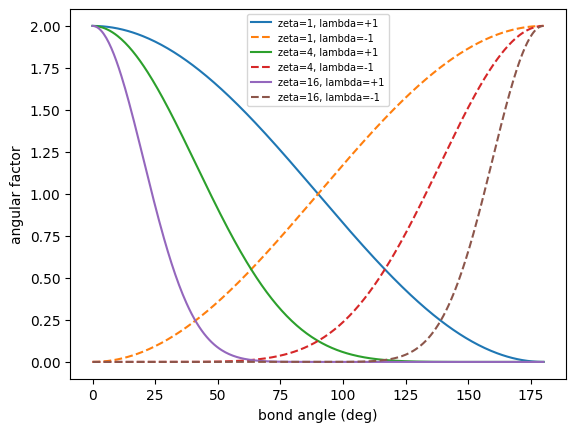

recovered angle: 104.5 deg


In [6]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()

# recover the angle of a single triplet from the two lambda values (zeta = 1)
true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

**Your turn.** Which $\zeta$ would you use to distinguish $100^\circ$ from $110^\circ$? Compute $(1-\cos\theta)^\zeta$ at both angles for $\zeta=1$ and $\zeta=16$ and compare the relative difference.

In [7]:
theta1, theta2 = np.deg2rad(100), np.deg2rad(110)

for zeta in (1, 16):
    val1 = (1 - np.cos(theta1))**zeta
    val2 = (1 - np.cos(theta2))**zeta
    rel_diff = abs(val1 - val2) / ((val1 + val2) / 2) * 100
    print(f"zeta = {zeta:2d} | 100 deg: {val1:.4f} | 110 deg: {val2:.4f} | Rel Diff: {rel_diff:.1f}%")

zeta =  1 | 100 deg: 1.1736 | 110 deg: 1.3420 | Rel Diff: 13.4%
zeta = 16 | 100 deg: 12.9601 | 110 deg: 110.6992 | Rel Diff: 158.1%
